In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.2
)

In [53]:
df = pd.read_csv(
    r"C:\Users\Clent\Documents\Programming\Python\Research\final_roselle\data\egfr\egfr_training_features.csv"
)
df = df.drop(
    columns=[
        "chembl_id",
        "compound_name",
        "inchikey",
        "smiles",
        "target_chembl_id",
        "target_label",
        "assay_chembl_id",
        "assay_type",
        "assay_confidence_score",
        "document_chembl_id",
        "standard_type",
        "activity_value",
        "activity_units",
        "p_activity_value",
        "pchembl_value",
        "chembl_molecular_weight",
    ]
)

In [65]:
def plot_hist(y, against):
    sns.histplot(y)
    plt.xlabel("pIC50")
    plt.ylabel("Frequency")
    plt.title(f"Distribution of pIC50 against {against}")
    plt.show()

def true_pred_comparison(y_true, y_test):
    sns.scatterplot(x=y_test, y=y_true)

    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linestyle="--"
    )

    plt.xlabel("Actual pIC50")
    plt.ylabel("Predicted pIC50")
    plt.title("Actual vs Predicted pIC50")
    plt.show()


In [55]:
df['pIC50'] = df.pop("pIC50")
df = df.dropna(subset=["chembl_alogp","chembl_qed_weighted"])

C:\Users\Clent\AppData\Local\Temp\ipykernel_3068\258836162.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pIC50'] = df.pop("pIC50")


In [56]:
null_rows = df[df.isnull().any(axis=1)]
null_rows

,chembl_alogp,chembl_qed_weighted,mol_weight,logp,tpsa,num_h_donors,num_h_acceptors,num_rotatable_bonds,num_aromatic_rings,num_rings,...,fp_1015,fp_1016,fp_1017,fp_1018,fp_1019,fp_1020,fp_1021,fp_1022,fp_1023,pIC50


In [57]:
fp_cols = [col for col in df.columns if col.startswith("fp_")]
unique_counts = df[fp_cols].nunique()
constant_fp = unique_counts[unique_counts == 1]


df = df.drop(columns=constant_fp.index)

In [58]:
X = df.drop(columns="pIC50")
y = df["pIC50"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [59]:
rf_regressor = RandomForestRegressor(
    n_estimators=200,
    criterion='squared_error', 
    random_state=25  
)

rf_regressor.fit(X_train, y_train)
y_pred = rf_regressor.predict(X_test)

In [60]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'RMSE: {rmse}')
print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')



RMSE: 0.7266122868351071
MSE: 0.5279654153797441
MAE: 0.5520346512734662
R2: 0.7108190032392396


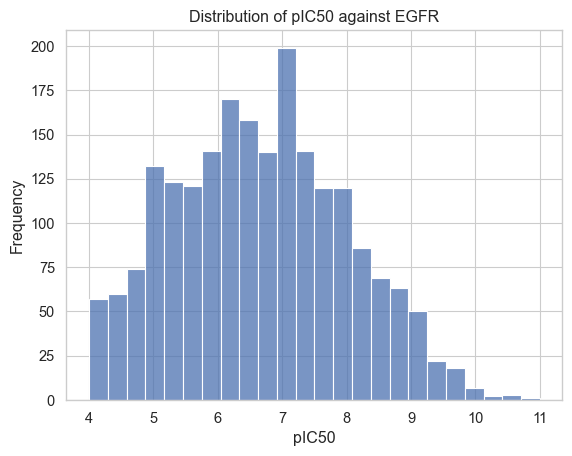

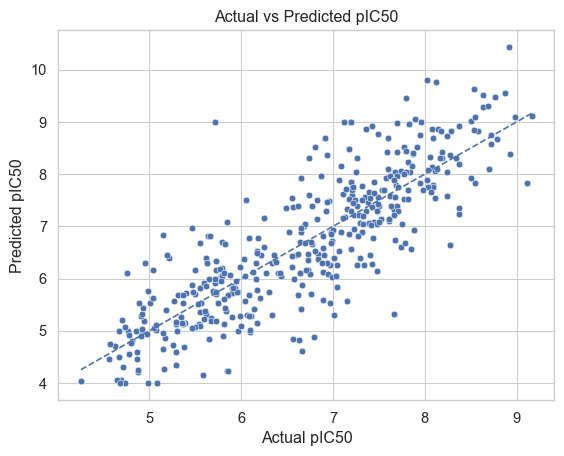

In [66]:
plot_hist(df.iloc[:, -1], against="EGFR")
true_pred_comparison(y_test, y_pred)